In [1]:
#https://www.10xgenomics.com/products/xenium-in-situ/preview-dataset-human-breast

In [1]:
# This notebook runs the image segmentation and morphology quantification for a region of interest.

In [2]:
from tifffile import imread
import matplotlib.pyplot as plt
#from utils import util
import os
import numpy as np

In [5]:
from utils import misc

This is utility function for Sc-HistoMorphics


2026-06-24 09:24:43.452953: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-24 09:24:44.564212: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-06-24 09:24:50.331558: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-06-24 09:24:50.357753: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-24 09:24:55.448229: W tensorflow/compiler/tf2t

In [6]:
import importlib

In [8]:
importlib.reload(misc)

This is utility function for Sc-HistoMorphics


<module 'utils.misc' from '/pod/2/activities/deepspace/team/elaheh/apps/segmentation_piepline/Sc-HistoMorphomics/src/schistomorphics/examples/utils/misc.py'>

In [7]:
%config Completer.use_jedi = False# tab shows function suggestions

# Script

In [15]:
%%time
img=imread("tile_hne.tif")

CPU times: user 1.89 ms, sys: 2.91 ms, total: 4.8 ms
Wall time: 5.11 ms


In [ ]:
he_url="https://cf.10xgenomics.com/samples/xenium/1.0.1/Xenium_FFPE_Human_Breast_Cancer_Rep1/Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.tif"
filename="/projects/activities/deepspace/data/spatial_transcriptome/Xenium/breastcancer/breastcancer_labels10.tiff"
h_e=imread("/projects/activities/deepspace/data/spatial_transcriptome/Xenium/breastcancer/Xenium_FFPE_Human_Breast_Cancer_Rep1_he_image.tif")
img=h_e[8000:9500,21500:23000,:]

In [ ]:
label_name

In [ ]:
%%time
# =============================================================================
# Image segmentation # takes about 5mins
# =============================================================================
labels=misc.segment_nuclei(img,label_name,prob_thresh=0.3,nms_thresh=0.1,force=False)

In [10]:
%%time
# =============================================================================
# Splitting channels and extracting morphology: takes about 5h
# =============================================================================
morph, hemo, eosin, cyto2 = misc.compute_or_load_morphology(
        img, labels2, "/projects/activities/deepspace/data/spatial_transcriptome/Xenium/breastcancer/breastcancer_Morphs2_testOriginal17",chunk_size=1500)

CellProfiler measurements not found. Computing...
mode intensity is customized by Elaheh and is only usable for this specific dataset://home/alizae/miniforge-pypy3/envs/stardist/lib/python3.8/site-packages/cellprofiler/modules/measureobjectintensity.py
mode is test


measureobjectintensitydistribution.py (1133): invalid value encountered in divide
_measurements.py (1408): invalid value encountered in divide
measureobjectneighbors.py (611): invalid value encountered in divide


Length of features is : 197
 Morph features shape is : (1464, 196)
CPU times: user 14min 38s, sys: 530 ms, total: 14min 39s
Wall time: 23.6 s


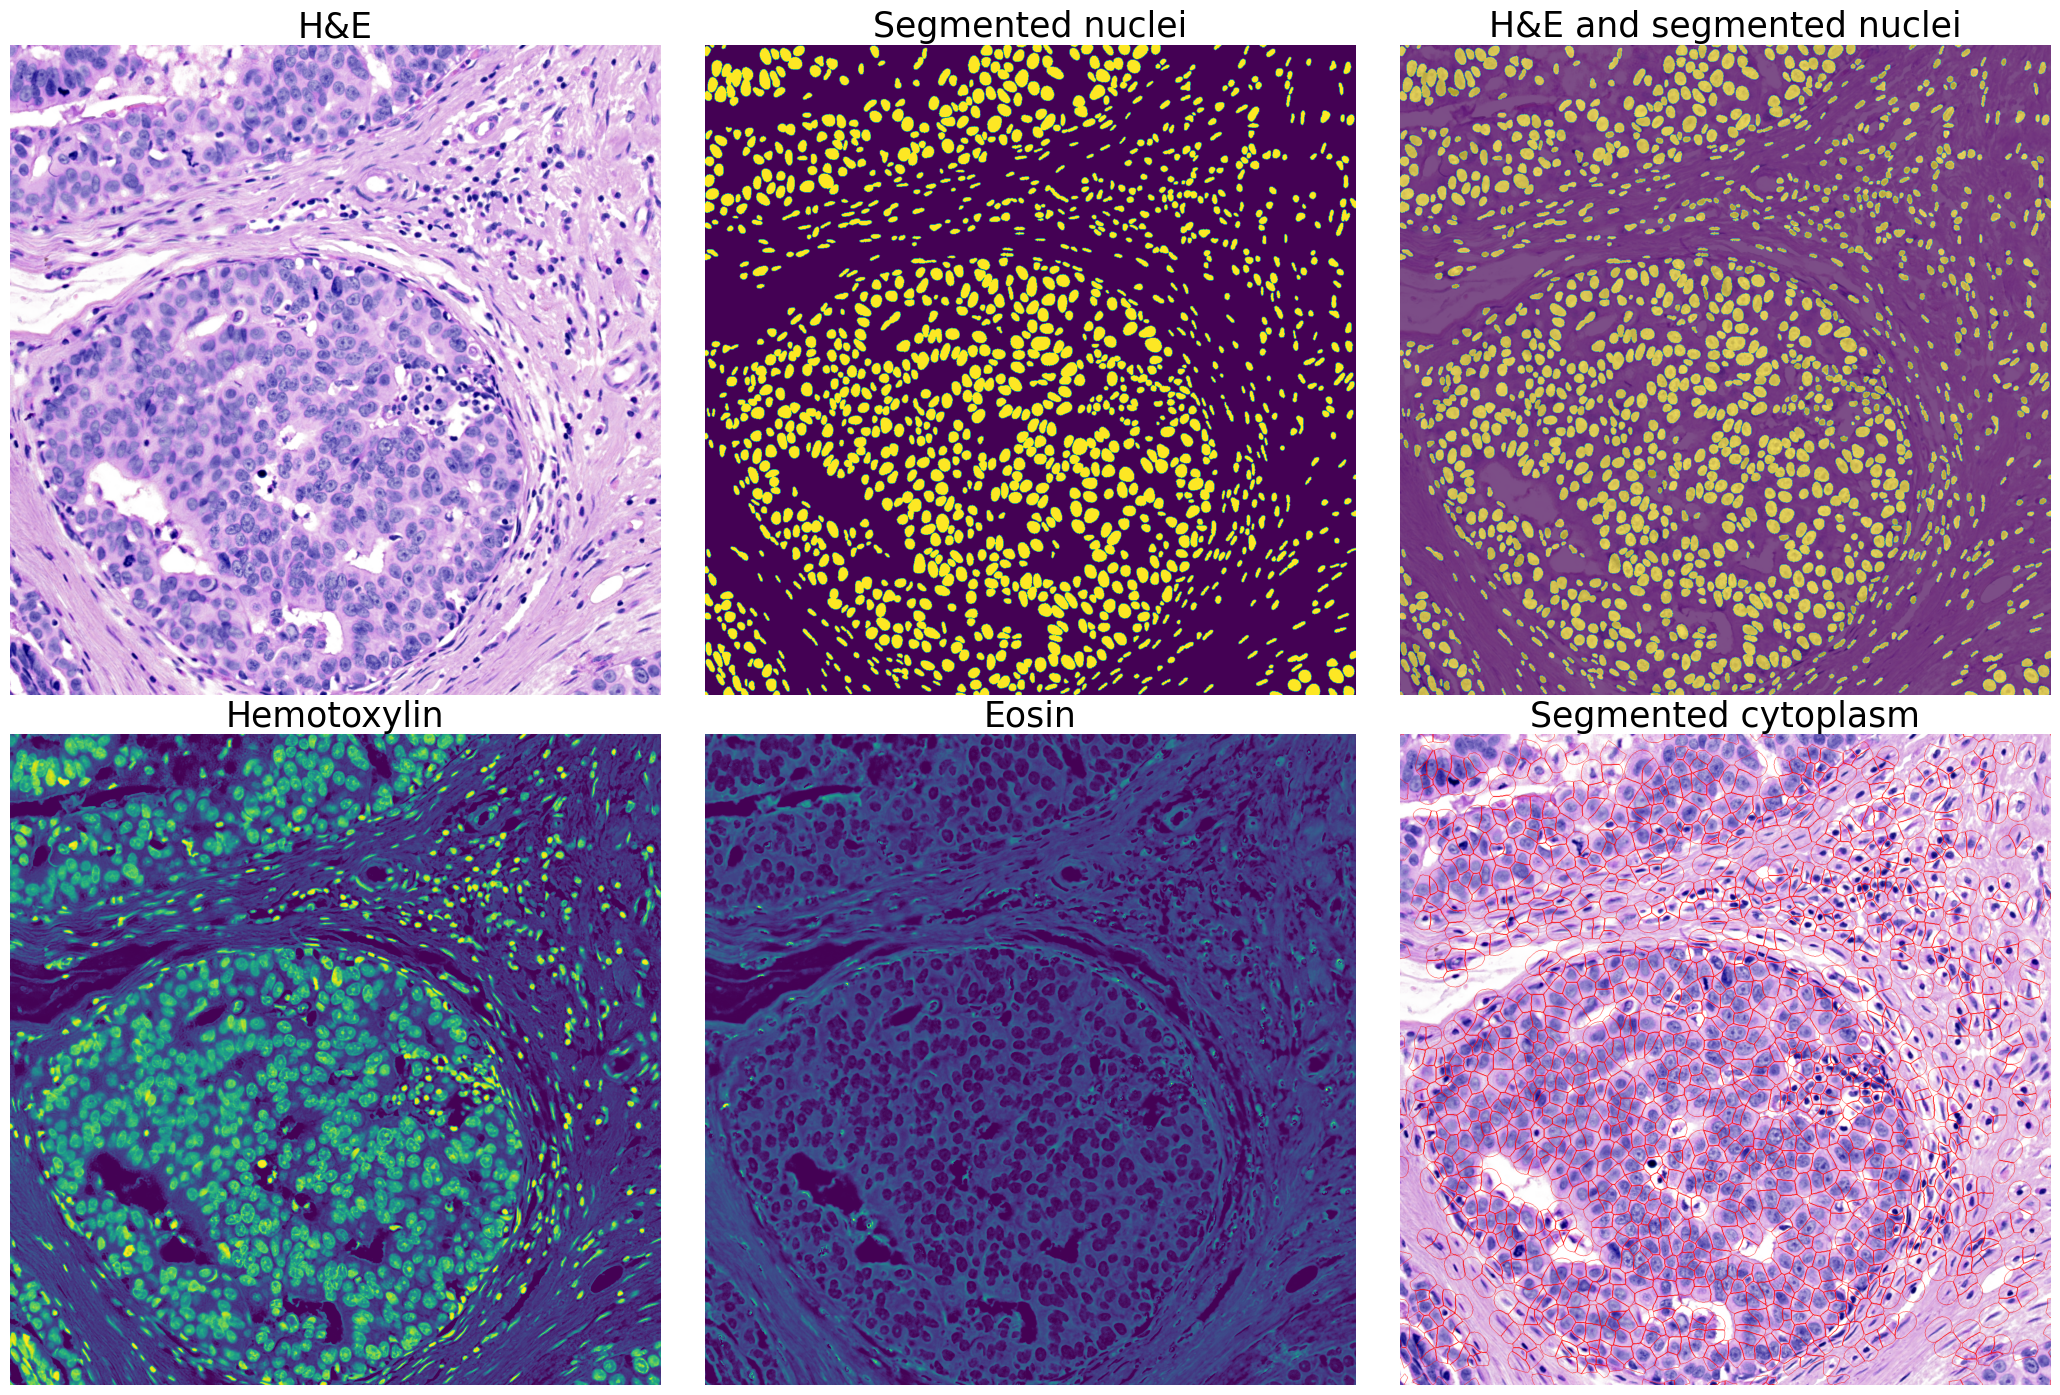

In [11]:
plt.figure(figsize=(21,14));

plt.subplot(2,3,1)
plt.imshow(img)
plt.axis("off")
plt.title("H&E",fontsize=25)


plt.subplot(2,3,2)
plt.imshow(labels2!=0)
plt.axis("off")
plt.title("Segmented nuclei",fontsize=25)

plt.subplot(2,3,3)
plt.imshow(img)
plt.imshow(labels2!=0,alpha=0.7)
plt.axis("off")
plt.title("H&E and segmented nuclei",fontsize=25)


plt.subplot(2,3,4)
plt.imshow(hemo)
plt.axis("off")
plt.title("Hemotoxylin",fontsize=25)


plt.subplot(2,3,5)
plt.imshow(eosin)
plt.axis("off")
plt.title("Eosin",fontsize=25)

plt.subplot(2,3,6)
plt.imshow(cyto2)
plt.axis("off")
plt.title("Segmented cytoplasm",fontsize=25)


# plt.figure(figsize=(10,10))
# plt.imshow(labels2!=0)
# plt.axis("off")
# plt.scatter(morph["AreaShape_Nuc_Center_col"],morph["AreaShape_Nuc_Center_row"],c="red",s=1)
# plt.title("Segmented nuclei & center of mass",fontsize=25);

plt.tight_layout()